# Lightweight fine-tuning of GPT-2 with LoRA

I take GPT-2, a 124M-parameter text *generator*, and turn it into a four-way news topic classifier by training about 0.24% of its weights with LoRA, using the Hugging Face `peft` library. The original model is evaluated first, exactly as downloaded. The fine-tuned model is then saved, loaded back from disk with the PEFT model class, and evaluated in the same way on the same test set, so the two can be compared directly.

## Where each project requirement is

| Rubric item | Section | What is shown there |
|---|---|---|
| Load a pretrained Hugging Face model | **Section 1** | `gpt2` loaded with `AutoModelForSequenceClassification` |
| Load and preprocess a dataset | **Section 2** | AG News from `datasets`, tokenized with GPT-2's `AutoTokenizer` |
| Evaluate the pretrained model | **Section 3** | The base model evaluated as-is on the test set: accuracy, precision, recall and F1 |
| Create a PEFT model | **Section 4** | `LoraConfig` + `get_peft_model` |
| Train the PEFT model | **Section 5** | 2 epochs with the Hugging Face `Trainer` |
| Save the PEFT model | **Section 6** | `save_pretrained` to `gpt2-lora-ag-news/`, next to this notebook |
| Load the saved PEFT model | **Section 7** | `AutoPeftModelForSequenceClassification.from_pretrained` |
| Evaluate the fine-tuned model | **Section 8** | The same evaluation as Section 3, then a side-by-side comparison |

After the eight sections I added two experiments of my own, because I wanted to understand *why* LoRA works as well as it does: how the result depends on the LoRA rank, and whether the frozen model can be stored in 4 bits (QLoRA) without losing accuracy.

## My choices

| Decision | Choice | Why |
|---|---|---|
| PEFT technique | LoRA | Covered in the course and recommended for the project. It works with every model PEFT supports |
| Model | `gpt2` (124M parameters) | Recommended for the project and small enough for a laptop or the workspace. It was trained to generate text, which makes turning it into a classifier an instructive exercise |
| Dataset | [AG News](https://huggingface.co/datasets/fancyzhx/ag_news) | A standard text-classification benchmark: four balanced classes (World, Sports, Business, Sci/Tech) with short texts that train quickly |
| Metrics | Accuracy, precision, recall, F1 | Accuracy as the headline; macro-averaged precision, recall and F1 so every class counts equally |

**Portability.** The notebook runs on current library versions (tested: `transformers` 5.19, `peft` 0.21, on an Apple Silicon GPU) and on older ones such as the course workspace. The three places that adapt to the installed version are marked *Compatibility 1, 2, 3 of 3*.

In [1]:
import inspect
import logging
import math
import os
import time
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
from matplotlib.colors import LinearSegmentedColormap

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
transformers.set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

# One plotting style for the whole notebook
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#eef5fe", "#2a78d6", "#0d366b"])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": SECONDARY,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
        "lines.linewidth": 2, "legend.frameon": False,
    }
)
os.makedirs("assets", exist_ok=True)

print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | device {DEVICE}")

torch 2.14.1 | transformers 5.19.0 | peft 0.21.2 | device mps


## Background: using a generator as a classifier

### Where the classification signal comes from

A BERT-style model is an *encoder*: every token attends to every other token, and the classifier reads the first position, `[CLS]`. GPT-2 is a *decoder* with a causal mask, so position $i$ can only attend to positions $\le i$. The first token has seen nothing but itself. The only position that has seen the whole input is the **last** one, so `GPT2ForSequenceClassification` reads the hidden state of the last non-padding token:

$$\mathbf{z} = W_{\text{score}}\;\mathbf{x}^{(L)}_{\,n}, \qquad W_{\text{score}} \in \mathbb{R}^{K \times 768},\quad n = \text{index of the last real token}.$$

That creates a practical requirement. To find "the last real token" in a padded batch the model needs to know which id means padding, and GPT-2 was trained without a padding token. I reuse the end-of-text token (id 50256) as padding and set `model.config.pad_token_id` to match.

### LoRA

LoRA (Hu et al., 2021) freezes a weight matrix $W_0$ and learns a low-rank update next to it:

$$\mathbf{h} = W_0\mathbf{x} + \frac{\alpha}{r}BA\,\mathbf{x}, \qquad A \in \mathbb{R}^{r\times d_{in}},\; B \in \mathbb{R}^{d_{out}\times r}.$$

$W_0$ stays fixed. Only the two small matrices $A$ and $B$ are trained. $B$ starts at zero, so at the start of training the model is exactly the pre-trained one.

### The parameter count, one step at a time

![Animation: counting LoRA parameters on GPT-2 step by step](assets/lora-parameter-count.gif)

**Step 1. Which matrix is adapted, and what shape is it?** In GPT-2 the query, key and value projections of an attention layer are stored together as one matrix called `c_attn`. Its input is a 768-dimensional token vector and its output is the three projections side by side: $d_{in} = 768$, $d_{out} = 3 \times 768 = 2304$. So the frozen $W_0$ has $2304 \times 768 = 1{,}769{,}472$ entries, none of them trained.

**Step 2. Size of $A$** ($r$ rows, $d_{in}$ columns), with rank $r = 8$: $\;8 \times 768 = 6{,}144.$

**Step 3. Size of $B$** ($d_{out}$ rows, $r$ columns): $\;2304 \times 8 = 18{,}432.$

**Step 4. One layer's adapter is $A$ plus $B$:** $\;6{,}144 + 18{,}432 = 24{,}576.$ The same number in one line is $r\,(d_{in} + d_{out}) = 8 \times 3072 = 24{,}576$.

**Step 5. GPT-2 has 12 layers, each with its own `c_attn`:** $\;12 \times 24{,}576 = 294{,}912.$

**Step 6. The classification head** maps 768 dimensions to $K = 4$ classes and has no bias: $\;4 \times 768 = 3{,}072.$

**Step 7. Total trained:** $\;294{,}912 + 3{,}072 = 297{,}984.$

**Step 8. As a share of the model** (124,442,880 parameters): $\;297{,}984 / 124{,}442{,}880 = 0.24\%.$

| Quantity | Calculation | Result |
|---|---|---:|
| $A$, one layer | $8 \times 768$ | 6,144 |
| $B$, one layer | $2304 \times 8$ | 18,432 |
| Adapter, one layer | $6{,}144 + 18{,}432$ | 24,576 |
| Adapters, 12 layers | $12 \times 24{,}576$ | 294,912 |
| Classification head | $4 \times 768$ | 3,072 |
| **Total trained** | $294{,}912 + 3{,}072$ | **297,984** |

Section 4 checks this total against what the library reports.

One implementation detail: GPT-2 stores these weights in a `Conv1D` layer whose matrix is the transpose of a normal `nn.Linear` weight. PEFT needs to be told so with `fan_in_fan_out=True`, otherwise the low-rank update is applied the wrong way round.

# Section 1: Load a pretrained Hugging Face model

`AutoModelForSequenceClassification` loads GPT-2's pre-trained transformer and puts a new linear layer (`score`) on top that maps the last token's hidden state to one score per class. That layer is the only thing that does not come from pre-training.

In [2]:
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "openai-community/gpt2"   # the namespaced id works on old and new library versions
LABELS = ["World", "Sports", "Business", "Sci/Tech"]
id2label = dict(enumerate(LABELS))
label2id = {name: i for i, name in id2label.items()}

# Compatibility 1 of 3: on Apple Silicon, PyTorch's fused attention kernel does not support
# dropout, so training needs the plain implementation there. Other devices use the default.
MODEL_KWARGS = {"attn_implementation": "eager"} if DEVICE == "mps" else {}


def load_base_model():
    """GPT-2 with a 4-way classification head, exactly as downloaded (no training)."""
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id, **MODEL_KWARGS
    )
    model.config.pad_token_id = model.config.eos_token_id   # id 50256, used for padding (see Background)
    return model


transformers.set_seed(42)
base_model = load_base_model()
total_params = sum(p.numel() for p in base_model.parameters())

print(f"model class          : {type(base_model).__name__}")
print(f"parameters           : {total_params:,}")
print(f"classification head  : {base_model.score}")
print(f"padding token id     : {base_model.config.pad_token_id}")

model class          : GPT2ForSequenceClassification
parameters           : 124,442,880
classification head  : Linear(in_features=768, out_features=4, bias=False)
padding token id     : 50256


# Section 2: Load and preprocess the dataset

AG News has 120,000 training and 7,600 test news items in four balanced classes. As the project allows, I use a subset to keep the run short: a random 4,000 items for training and 1,000 for testing, with a fixed seed so every run uses the same items. **The same 1,000 test items are used for every evaluation in this notebook.**

The texts are tokenized with GPT-2's own tokenizer and truncated at 128 tokens (the longest AG News item in this sample is 128 tokens after truncation; the median is about 50). Padding is added per batch by `DataCollatorWithPadding`.

In [3]:
import datasets
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

datasets.disable_progress_bars()

raw = load_dataset("fancyzhx/ag_news")
splits = {
    "train": raw["train"].shuffle(seed=42).select(range(4000)),
    "test": raw["test"].shuffle(seed=42).select(range(1000)),
}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token   # GPT-2 has no padding token of its own


def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)


tokenized = {name: ds.map(tokenize, batched=True) for name, ds in splits.items()}
collator = DataCollatorWithPadding(tokenizer=tokenizer)
y_test = np.array(tokenized["test"]["label"])

lengths = [len(ids) for ids in tokenized["train"]["input_ids"]]
print(f"tokens per item: median {np.median(lengths):.0f}, 95th percentile {np.percentile(lengths, 95):.0f}, max {max(lengths)}")
for name in splits:
    counts = np.bincount(splits[name]["label"], minlength=4)
    print(f"{name:5s}: {len(splits[name]):,} items | " + ", ".join(f"{LABELS[i]} {c}" for i, c in enumerate(counts)))
print(f"columns after tokenization: {tokenized['train'].column_names}")

pd.set_option("display.max_colwidth", 110)
pd.DataFrame({"text": splits["train"]["text"][:4], "label": [LABELS[i] for i in splits["train"]["label"][:4]]})

tokens per item: median 50, 95th percentile 79, max 128
train: 4,000 items | World 1007, Sports 1000, Business 942, Sci/Tech 1051
test : 1,000 items | World 266, Sports 246, Business 246, Sci/Tech 242
columns after tokenization: ['text', 'label', 'input_ids', 'attention_mask']


,text,label
0,Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a...,World
1,Desiring Stability Redskins coach Joe Gibbs expects few major personnel changes in the offseason and wants...,Sports
2,"Will Putin #39;s Power Play Make Russia Safer? Outwardly, Russia has not changed since the barrage of terr...",World
3,U2 pitches for Apple New iTunes ads airing during baseball games Tuesday will feature the advertising-shy ...,Sci/Tech


# Section 3: Evaluate the pretrained (base) model

Here the base model from Section 1 is evaluated **as-is: no training, no fine-tuning, no changes to its weights.** It is run over the 1,000 test items with the Hugging Face `Trainer.evaluate()` method, and four classification metrics are computed.

For each class $k$, with true positives $TP_k$, false positives $FP_k$ and false negatives $FN_k$:

$$\text{precision}_k = \frac{TP_k}{TP_k + FP_k}, \qquad \text{recall}_k = \frac{TP_k}{TP_k + FN_k}, \qquad F_1^{(k)} = \frac{2\,\text{precision}_k\,\text{recall}_k}{\text{precision}_k + \text{recall}_k}.$$

- **Accuracy** is the share of all test items classified correctly.
- **Precision, recall and F1** are *macro*-averaged: computed for each of the four classes and then averaged, so each class counts equally.

With four balanced classes, random guessing scores about 25% on each.

The exact same `Trainer` settings and `compute_metrics` function are reused in Section 8 for the fine-tuned model.

In [4]:
from transformers import PrinterCallback, Trainer, TrainingArguments


def confusion(labels, preds, k=len(LABELS)):
    matrix = np.zeros((k, k), dtype=int)
    np.add.at(matrix, (labels, preds), 1)
    return matrix


def compute_metrics(eval_pred):
    """Accuracy and macro-averaged precision, recall and F1."""
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    cm = confusion(labels, preds)
    tp = np.diag(cm).astype(float)
    precision = np.divide(tp, cm.sum(axis=0), out=np.zeros(len(LABELS)), where=cm.sum(axis=0) > 0)
    recall = np.divide(tp, cm.sum(axis=1), out=np.zeros(len(LABELS)), where=cm.sum(axis=1) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(LABELS)), where=(precision + recall) > 0)
    return {
        "accuracy": float((preds == labels).mean()),
        "precision": float(precision.mean()),
        "recall": float(recall.mean()),
        "f1": float(f1.mean()),
    }


# Compatibility 2 of 3: this argument was renamed from evaluation_strategy to eval_strategy.
EVAL_KEY = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"

# Evaluation-only settings, shared by Section 3 (base model) and Section 8 (fine-tuned model)
eval_args = TrainingArguments(
    output_dir="./data/evaluation",
    per_device_eval_batch_size=32,
    label_names=["labels"],     # lets the Trainer report metrics for PEFT-wrapped models too
    report_to="none",
    dataloader_pin_memory=False,
    disable_tqdm=True,
)

# Compatibility 3 of 3: the tokenizer reaches the Trainer through the data collator only,
# because the Trainer's own tokenizer argument was renamed between versions.
base_trainer = Trainer(
    model=base_model,
    args=eval_args,
    eval_dataset=tokenized["test"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)
base_trainer.remove_callback(PrinterCallback)   # print a clean summary below instead of the raw log line
base_results = base_trainer.evaluate()
base_preds = np.argmax(base_trainer.predict(tokenized["test"]).predictions, axis=1)

print("Base model (pretrained GPT-2, no training), 1,000 test items:")
for metric in ["accuracy", "precision", "recall", "f1"]:
    print(f"  {metric:9s}: {base_results['eval_' + metric]:.3f}")
base_results

Base model (pretrained GPT-2, no training), 1,000 test items:
  accuracy : 0.270
  precision: 0.245
  recall   : 0.254
  f1       : 0.115


{'eval_loss': 4.635315418243408,
 'eval_model_preparation_time': 0.0007,
 'eval_accuracy': 0.27,
 'eval_precision': 0.24528844770536612,
 'eval_recall': 0.2542254396321382,
 'eval_f1': 0.1152824164011088,
 'eval_runtime': 4.5664,
 'eval_samples_per_second': 218.991,
 'eval_steps_per_second': 7.008,
 'epoch': 0}

In [5]:
# Where the base model's predictions go
base_cm = confusion(y_test, base_preds)
pd.DataFrame(base_cm, index=[f"actual {l}" for l in LABELS], columns=[f"predicted {l}" for l in LABELS])

,predicted World,predicted Sports,predicted Business,predicted Sci/Tech
actual World,265,0,0,1
actual Sports,246,0,0,0
actual Business,245,0,0,1
actual Sci/Tech,237,0,0,5


**Base model result: accuracy 27.0%, precision 0.245, recall 0.254, F1 0.115.**

The confusion matrix shows what is happening: the base model answers "World" for 993 of the 1,000 items. Its accuracy is therefore just the share of World items in the test set (266 of 1,000, plus the handful of others it happens to get right), and the macro-F1 of 0.115 shows that three of the four classes are essentially never predicted.

This is the expected behaviour of the pretrained model as-is. GPT-2's transformer layers are pre-trained, but the `score` layer that turns them into four class scores has never seen a labelled example, so its output is an arbitrary linear read-out that happens to favour one class. The next cell measures the pretrained model a second way, without any added layer at all.

## Section 3 (continued): the pretrained GPT-2 as a zero-shot classifier

The base model above has a classification layer that has never been trained, so its 27% partly reflects that layer, not what GPT-2 knows. To measure the pretrained model *without adding anything to it*, I also use GPT-2 exactly as it was published, as a language model, and let it pick a topic by itself.

Each test item is turned into a prompt that ends in a sentence for GPT-2 to complete:

> *{news text}* ⏎ This article is about

GPT-2 then scores the four possible next words, ` world`, ` sports`, ` business` and ` science`, and the most probable one is the prediction:

$$\hat{y} = \arg\max_{k}\; P_{\text{GPT-2}}\big(\text{word}_k \mid \text{prompt}\big).$$

No weights are added or changed. The same 1,000 test items and the same metrics are used.

In [6]:
from transformers import AutoModelForCausalLM

LABEL_WORDS = [" world", " sports", " business", " science"]
label_token_ids = [tokenizer.encode(word)[0] for word in LABEL_WORDS]   # each is a single GPT-2 token

lm = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **MODEL_KWARGS).to(DEVICE).eval()


@torch.no_grad()
def zero_shot_predict(texts, batch_size=32):
    preds = []
    for start in range(0, len(texts), batch_size):
        prompts = []
        for text in texts[start:start + batch_size]:
            body = tokenizer.decode(tokenizer.encode(text)[:120])     # keep the prompt short
            prompts.append(f"{body}\nThis article is about")
        batch = tokenizer(prompts, return_tensors="pt", padding=True).to(DEVICE)
        logits = lm(**batch).logits
        last = batch["attention_mask"].sum(dim=1) - 1                  # position of the last real token
        next_token_logits = logits[torch.arange(len(prompts)), last]
        preds.extend(next_token_logits[:, label_token_ids].argmax(dim=1).tolist())
    return np.array(preds)


zero_shot_preds = zero_shot_predict(list(splits["test"]["text"]))
zero_shot_results = {f"eval_{k}": v for k, v in compute_metrics((np.eye(4)[zero_shot_preds], y_test)).items()}
del lm

print("Pretrained GPT-2 as a zero-shot classifier (no new layer, no training), 1,000 test items:")
for metric in ["accuracy", "precision", "recall", "f1"]:
    print(f"  {metric:9s}: {zero_shot_results['eval_' + metric]:.3f}")

Pretrained GPT-2 as a zero-shot classifier (no new layer, no training), 1,000 test items:
  accuracy : 0.625
  precision: 0.701
  recall   : 0.623
  f1       : 0.607


**Zero-shot result: accuracy 62.5%, precision 0.701, recall 0.623, F1 0.607.**

Used purely as the language model it was trained to be, GPT-2 already knows a fair amount about news topics: 62.5% is far above the 25% of chance. Its main weakness is Sci/Tech, which it recognizes only 23% of the time, labelling most technology stories "business". That is a reasonable reading for news about technology companies, and it is exactly the kind of label convention that a few thousand labelled examples can teach.

Both baselines use the same 1,000 test items and the same four metrics as the fine-tuned model in Section 8.

# Section 4: Create a PEFT model

The config says which matrices get an adapter and how large it is:

| Argument | Value | Meaning |
|---|---|---|
| `task_type` | `TaskType.SEQ_CLS` | Sequence classification, so PEFT also trains and **saves** the new `score` head along with the adapters |
| `r` | 8 | Rank of the update $BA$ |
| `lora_alpha` | 16 | Scaling numerator; the update is multiplied by $\alpha/r = 2$ |
| `lora_dropout` | 0.1 | Dropout on the adapter's input during training |
| `target_modules` | `["c_attn"]` | The combined query/key/value projection in each of the 12 layers |
| `fan_in_fan_out` | `True` | GPT-2's `Conv1D` stores its weight transposed |

`get_peft_model` wraps a fresh copy of the base model, freezes every original weight and inserts the adapters.

In [7]:
from peft import LoraConfig, TaskType, get_peft_model


def make_lora_config(r=8):
    return LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=r,
        lora_alpha=2 * r,           # keeps the scale alpha / r = 2 for every rank
        lora_dropout=0.1,
        target_modules=["c_attn"],
        fan_in_fan_out=True,
    )


lora_config = make_lora_config(r=8)
transformers.set_seed(42)
peft_model = get_peft_model(load_base_model(), lora_config)

print(f"model class: {type(peft_model).__name__}")
peft_model.print_trainable_parameters()

# Check the hand count from the Background section
trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
adapter_params = 12 * 8 * (768 + 2304)
head_params = len(LABELS) * 768
assert trainable == adapter_params + head_params == 297_984
lora_layers = [name for name, _ in peft_model.named_modules() if name.endswith("c_attn.lora_A.default")]
print(f"by hand: 12 layers x 8 x (768 + 2304) = {adapter_params:,} adapter + {head_params:,} head = {adapter_params + head_params:,}")
print(f"LoRA adapters inserted: {len(lora_layers)} (one per transformer layer)")
print(f"modules trained in full and saved with the adapter: {peft_model.peft_config['default'].modules_to_save}")

model class: PeftModelForSequenceClassification
trainable params: 297,984 || all params: 124,740,864 || trainable%: 0.2389
by hand: 12 layers x 8 x (768 + 2304) = 294,912 adapter + 3,072 head = 297,984
LoRA adapters inserted: 12 (one per transformer layer)
modules trained in full and saved with the adapter: ['classifier', 'score']


# Section 5: Train the PEFT model

Two epochs over the 4,000 training items with the Hugging Face `Trainer`. Only the 297,984 adapter and head parameters receive updates; the other 124.4M stay exactly as pre-trained.

The learning rate is $5\times10^{-4}$, higher than the $2\times10^{-5}$ typical for full fine-tuning, for a simple reason: the adapters and the head start from zero or random values, so there is no pre-trained knowledge in *them* to protect, and the pre-trained weights themselves cannot move. Checkpoint saving is turned off during training (`save_strategy="no"`) because the adapter is saved explicitly in Section 6, which also keeps the workspace small.

In [8]:
train_args = TrainingArguments(
    output_dir="./data/training",
    learning_rate=5e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    save_strategy="no",
    logging_steps=25,
    label_names=["labels"],
    seed=42,
    report_to="none",
    dataloader_pin_memory=False,
    disable_tqdm=True,
    **{EVAL_KEY: "epoch"},
)

peft_trainer = Trainer(
    model=peft_model,
    args=train_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["test"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)
peft_trainer.remove_callback(PrinterCallback)   # keep the output short; the loss curve is plotted below

train_output = peft_trainer.train()

history = pd.DataFrame(peft_trainer.state.log_history)
print(f"device: {peft_model.device} | epochs: 2 | optimizer steps: {train_output.global_step} | wall time: {train_output.metrics['train_runtime']:.0f}s")
history.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]].round(4)

device: mps:0 | epochs: 2 | optimizer steps: 500 | wall time: 81s


,epoch,eval_loss,eval_accuracy,eval_f1
10,1.0,0.3164,0.891,0.8908
21,2.0,0.3009,0.894,0.8939


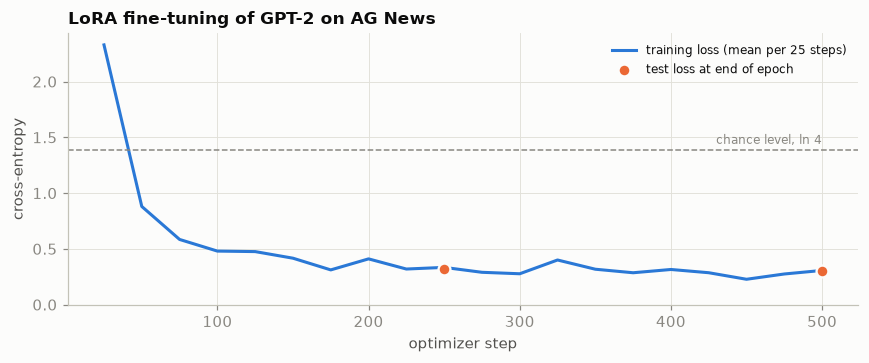

In [9]:
# Figure 1: training loss
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(train_log["step"], train_log["loss"], color=BLUE, label="training loss (mean per 25 steps)")
ax.scatter(eval_log["step"], eval_log["eval_loss"], color=ORANGE, s=60, zorder=3, edgecolor=SURFACE, linewidth=1.5,
           label="test loss at end of epoch")
ax.axhline(np.log(4), color=MUTED, linestyle="--", linewidth=1)
ax.annotate("chance level, ln 4", xy=(train_log["step"].max(), np.log(4)), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=8, color=MUTED)
ax.set(xlabel="optimizer step", ylabel="cross-entropy", title="LoRA fine-tuning of GPT-2 on AG News", ylim=(0, None))
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig("assets/training-curve.png")
plt.show()

# Predictions of the trained model while it is still in memory, kept to check the reload in Section 7
in_memory_preds = np.argmax(peft_trainer.predict(tokenized["test"]).predictions, axis=1)

# Section 6: Save the PEFT model

`save_pretrained` on a PEFT model writes only what was trained: the LoRA matrices and the classification head. The 124M frozen GPT-2 weights are not copied; they are downloaded again from the Hub when the adapter is loaded. I also save the tokenizer into the same directory, so the folder contains everything needed to use the model besides the public GPT-2 weights. The directory sits in the same folder as this notebook.

In [10]:
ADAPTER_DIR = "gpt2-lora-ag-news"

peft_model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

saved = {name: os.path.getsize(os.path.join(ADAPTER_DIR, name)) for name in sorted(os.listdir(ADAPTER_DIR))}
for name, size in saved.items():
    print(f"{ADAPTER_DIR}/{name:28s} {size / 1024:9.1f} KB")
adapter_mb = os.path.getsize(os.path.join(ADAPTER_DIR, "adapter_model.safetensors")) / 1024**2
print(f"\nadapter weights: {adapter_mb:.2f} MB   vs   a full 32-bit copy of GPT-2: {total_params * 4 / 1024**2:.0f} MB")

gpt2-lora-ag-news/README.md                          5.0 KB
gpt2-lora-ag-news/adapter_config.json                1.1 KB
gpt2-lora-ag-news/adapter_model.safetensors       1167.1 KB
gpt2-lora-ag-news/tokenizer.json                  3474.5 KB
gpt2-lora-ag-news/tokenizer_config.json              0.3 KB

adapter weights: 1.14 MB   vs   a full 32-bit copy of GPT-2: 475 MB


# Section 7: Load the saved PEFT model

To show that the saved files are sufficient on their own, every model object is deleted from memory first. The fine-tuned model is then rebuilt from the `gpt2-lora-ag-news/` directory with **`AutoPeftModelForSequenceClassification`**, the PEFT model class for sequence classification. It reads `adapter_config.json`, loads the GPT-2 base model named there, and attaches the saved LoRA adapters and classification head.

Two details matter when reloading, and getting either wrong makes a reloaded model score differently from the one that was saved:

1. **`num_labels` must be passed again.** Without it the base model is built with a 2-way head that the saved 4-way head cannot be loaded into.
2. **`pad_token_id` must be set again**, so GPT-2 can find the last real token (see Background).

The library reports **0 trainable parameters** after loading. That is expected: `from_pretrained` loads a PEFT model for inference by default, with the adapter frozen. The 297,984 trained values are all there; they are just not being trained any more.

In [11]:
from peft import AutoPeftModelForSequenceClassification, PeftModel

del peft_model, peft_trainer, base_model, base_trainer   # nothing trained remains in memory

loaded_model = AutoPeftModelForSequenceClassification.from_pretrained(
    ADAPTER_DIR,
    num_labels=len(LABELS),
    id2label=id2label,
    label2id=label2id,
    **MODEL_KWARGS,
)
loaded_model.config.pad_token_id = loaded_model.config.eos_token_id
loaded_tokenizer = AutoTokenizer.from_pretrained(ADAPTER_DIR)

assert isinstance(loaded_model, PeftModel)
print(f"loaded with  : AutoPeftModelForSequenceClassification")
print(f"model class  : {type(loaded_model).__name__}  (a PeftModel: {isinstance(loaded_model, PeftModel)})")
print(f"base model   : {loaded_model.peft_config['default'].base_model_name_or_path}")
print(f"PEFT method  : {loaded_model.peft_config['default'].peft_type.value}, rank {loaded_model.peft_config['default'].r}")
print(f"LoRA layers  : {sum(1 for n, _ in loaded_model.named_modules() if n.endswith('lora_A.default'))}")
loaded_model.print_trainable_parameters()

loaded with  : AutoPeftModelForSequenceClassification
model class  : PeftModelForSequenceClassification  (a PeftModel: True)
base model   : openai-community/gpt2
PEFT method  : LORA, rank 8
LoRA layers  : 12
trainable params: 0 || all params: 124,740,864 || trainable%: 0.0000


# Section 8: Evaluate the fine-tuned model and compare it with the base model

The loaded PEFT model is evaluated with **exactly the same process as the base model in Section 3**: the same `eval_args`, the same `compute_metrics` function, the same 1,000 test items, through `Trainer.evaluate()`.

In [12]:
loaded_trainer = Trainer(
    model=loaded_model,
    args=eval_args,
    eval_dataset=tokenized["test"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)
loaded_trainer.remove_callback(PrinterCallback)
peft_results = loaded_trainer.evaluate()
peft_preds = np.argmax(loaded_trainer.predict(tokenized["test"]).predictions, axis=1)

# The model loaded from disk must reproduce the model that was trained, prediction for prediction
assert np.array_equal(peft_preds, in_memory_preds), "loaded model differs from the trained one"

print("Fine-tuned PEFT model (loaded from disk), 1,000 test items:")
for metric in ["accuracy", "precision", "recall", "f1"]:
    print(f"  {metric:9s}: {peft_results['eval_' + metric]:.3f}")
print("\nThe loaded model's predictions match the trained model's on all 1,000 test items.")
peft_results

Fine-tuned PEFT model (loaded from disk), 1,000 test items:
  accuracy : 0.894
  precision: 0.895
  recall   : 0.894
  f1       : 0.894

The loaded model's predictions match the trained model's on all 1,000 test items.


{'eval_loss': 0.3009326756000519,
 'eval_model_preparation_time': 0.0012,
 'eval_accuracy': 0.894,
 'eval_precision': 0.8945874539012588,
 'eval_recall': 0.8944208434814107,
 'eval_f1': 0.8938985448939535,
 'eval_runtime': 4.4603,
 'eval_samples_per_second': 224.202,
 'eval_steps_per_second': 7.174,
 'epoch': 0}

## 8.1 Side-by-side comparison

In [13]:
rows = [
    ("Base GPT-2 with untrained head (Section 3)", base_results, "0"),
    ("Base GPT-2, zero-shot (Section 3, continued)", zero_shot_results, "0"),
    ("GPT-2 + LoRA, loaded with AutoPeftModel (Section 8)", peft_results, f"{trainable:,}"),
]
comparison = pd.DataFrame(
    {
        "trained parameters": [r[2] for r in rows],
        "accuracy": [r[1]["eval_accuracy"] for r in rows],
        "precision": [r[1]["eval_precision"] for r in rows],
        "recall": [r[1]["eval_recall"] for r in rows],
        "F1": [r[1]["eval_f1"] for r in rows],
    },
    index=[r[0] for r in rows],
)

best_base_accuracy = max(base_results["eval_accuracy"], zero_shot_results["eval_accuracy"])
assert peft_results["eval_accuracy"] > best_base_accuracy
print(f"Accuracy gain over the base model with its untrained head: {peft_results['eval_accuracy'] - base_results['eval_accuracy']:+.1%} "
      f"({base_results['eval_accuracy']:.1%} -> {peft_results['eval_accuracy']:.1%})")
print(f"Accuracy gain over the zero-shot base model:               {peft_results['eval_accuracy'] - zero_shot_results['eval_accuracy']:+.1%} "
      f"({zero_shot_results['eval_accuracy']:.1%} -> {peft_results['eval_accuracy']:.1%})")
comparison.round(3)

Accuracy gain over the base model with its untrained head: +62.4% (27.0% -> 89.4%)
Accuracy gain over the zero-shot base model:               +26.9% (62.5% -> 89.4%)


,trained parameters,accuracy,precision,recall,F1
Base GPT-2 with untrained head (Section 3),0,0.270,0.245,0.254,0.115
"Base GPT-2, zero-shot (Section 3, continued)",0,0.625,0.701,0.623,0.607
"GPT-2 + LoRA, loaded with AutoPeftModel (Section 8)","297,984",0.894,0.895,0.894,0.894


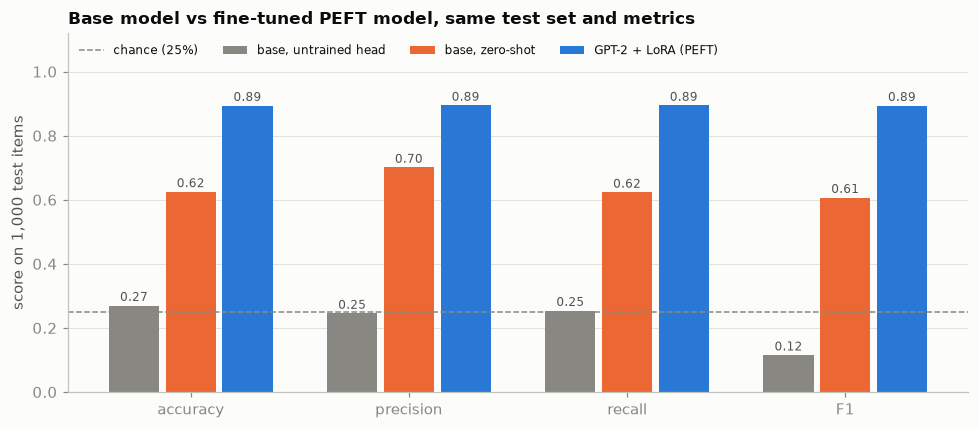

In [14]:
# Figure 2: the four metrics for each model
metrics = ["accuracy", "precision", "recall", "F1"]
series = [
    ("base, untrained head", comparison.iloc[0], MUTED),
    ("base, zero-shot", comparison.iloc[1], ORANGE),
    ("GPT-2 + LoRA (PEFT)", comparison.iloc[2], BLUE),
]
x = np.arange(len(metrics))
width = 0.26

fig, ax = plt.subplots(figsize=(9, 4))
for i, (name, row, color) in enumerate(series):
    bars = ax.bar(x + (i - 1) * width, [row[m] for m in metrics], width - 0.03, color=color, label=name)
    for bar in bars:
        ax.annotate(f"{bar.get_height():.2f}", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=SECONDARY)
ax.axhline(0.25, color=MUTED, linestyle="--", linewidth=1, label="chance (25%)")
ax.set(xticks=x, xticklabels=metrics, ylim=(0, 1.12), ylabel="score on 1,000 test items",
       title="Base model vs fine-tuned PEFT model, same test set and metrics")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=8, ncol=4)
fig.tight_layout()
fig.savefig("assets/comparison.png")
plt.show()

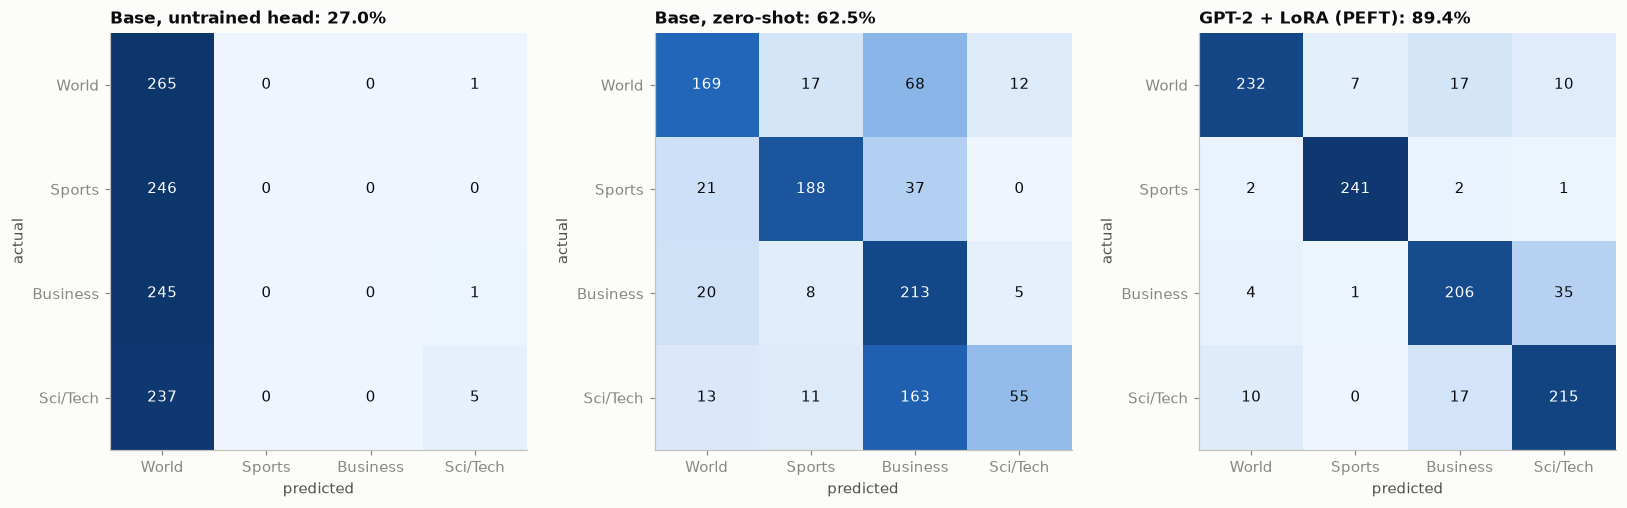

,test items,"recall, base (untrained head)","recall, base (zero-shot)","recall, GPT-2 + LoRA"
World,266,0.996,0.635,0.872
Sports,246,0.000,0.764,0.980
Business,246,0.000,0.866,0.837
Sci/Tech,242,0.021,0.227,0.888


In [15]:
# Figure 3: where each model puts its predictions
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, preds, title in [
    (axes[0], base_preds, f"Base, untrained head: {base_results['eval_accuracy']:.1%}"),
    (axes[1], zero_shot_preds, f"Base, zero-shot: {zero_shot_results['eval_accuracy']:.1%}"),
    (axes[2], peft_preds, f"GPT-2 + LoRA (PEFT): {peft_results['eval_accuracy']:.1%}"),
]:
    cm = confusion(y_test, preds)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=10, color="white" if share[i, j] > 0.55 else INK)
    ax.set(xticks=range(4), yticks=range(4), xticklabels=LABELS, yticklabels=LABELS, xlabel="predicted", ylabel="actual", title=title)
    ax.grid(False)
fig.tight_layout()
fig.savefig("assets/before-after.png")
plt.show()

per_class = pd.DataFrame(
    {
        "test items": np.bincount(y_test, minlength=4),
        "recall, base (untrained head)": np.diag(confusion(y_test, base_preds)) / np.bincount(y_test, minlength=4),
        "recall, base (zero-shot)": np.diag(confusion(y_test, zero_shot_preds)) / np.bincount(y_test, minlength=4),
        "recall, GPT-2 + LoRA": np.diag(confusion(y_test, peft_preds)) / np.bincount(y_test, minlength=4),
    },
    index=LABELS,
)
per_class.round(3)

## 8.2 Is the improvement real?

The base and fine-tuned models were scored on the *same* 1,000 items, so the right test is a paired one. **McNemar's test** looks only at the items where the two models disagree. Let $b$ be the number the fine-tuned model gets right and the base model gets wrong, and $c$ the reverse. If the two models were equally accurate, each disagreement would be a coin flip, so under that hypothesis $b \sim \text{Binomial}(b + c, \tfrac12)$, and the exact p-value is the probability of a split at least as lopsided as the one observed.

In [16]:
def mcnemar_exact(preds_a, preds_b):
    only_a = int(((preds_a == y_test) & (preds_b != y_test)).sum())
    only_b = int(((preds_a != y_test) & (preds_b == y_test)).sum())
    n, k = only_a + only_b, min(only_a, only_b)
    p_value = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2**n) if n else 1.0
    return only_a, only_b, p_value


for name, preds in [("untrained head", base_preds), ("zero-shot", zero_shot_preds)]:
    only_peft, only_base, p = mcnemar_exact(peft_preds, preds)
    print(f"PEFT vs base ({name:14s}): only PEFT correct {only_peft:3d} | only base correct {only_base:3d} | exact p-value {p:.1e}")

PEFT vs base (untrained head): only PEFT correct 659 | only base correct  35 | exact p-value 2.9e-150
PEFT vs base (zero-shot     ): only PEFT correct 311 | only base correct  42 | exact p-value 7.2e-52


## 8.3 The same test items, side by side

In [17]:
sample = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pd.DataFrame(
    {
        "text": [splits["test"]["text"][i][:95] + "..." for i in sample],
        "true label": [LABELS[y_test[i]] for i in sample],
        "base (untrained head)": [LABELS[base_preds[i]] for i in sample],
        "base (zero-shot)": [LABELS[zero_shot_preds[i]] for i in sample],
        "GPT-2 + LoRA": [LABELS[peft_preds[i]] for i in sample],
    }
)

,text,true label,base (untrained head),base (zero-shot),GPT-2 + LoRA
0,Indian board plans own telecast of Australia series The Indian cricket board said on Wednesday ...,Sports,World,Sports,Sports
1,Stocks Higher on Drop in Jobless Claims A sharp drop in initial unemployment claims and bullish...,Business,World,Business,Business
2,"Nuggets 112, Raptors 106 Carmelo Anthony scored 30 points and Kenyon Martin added 24 points and...",Sports,World,Sports,Sports
3,Stocks Higher on Drop in Jobless Claims A sharp drop in initial unemployment claims and bullish...,Business,World,Business,Business
4,REVIEW: 'Half-Life 2' a Tech Masterpiece (AP) AP - It's been six years since Valve Corp. perfec...,Sci/Tech,World,Sci/Tech,Sci/Tech
5,China's inflation rate slows sharply but problems remain (AFP) AFP - China's inflation rate eas...,World,World,Business,Business
6,"ADV: Try Currency Trading Risk-Free 30 Days 24-hour commission-free trading, 100-to-1 leverage ...",Business,World,Business,Business
7,OPEC Can Raise Output Capacity by 1 Mln Barrels/Day (Update1) The Organization of Petroleum Exp...,Business,World,World,Business
8,"Intel gets off chip speed roller coaster: Technology India: New York, Oct 19 : The world #39;s ...",Sci/Tech,World,Business,Sci/Tech
9,Amazon Snaps Up China's Largest Web Retailer (NewsFactor) NewsFactor - Amazon.com (Nasdaq: AMZN...,Business,World,Business,Business


## 8.4 The fine-tuned model on new text

A few headlines I wrote myself, to see the loaded PEFT model work on inputs that are not from the dataset, using the tokenizer that was saved with it.

In [18]:
headlines = [
    "Central bank raises interest rates for the third time this year as inflation stays high",
    "Striker scores twice in stoppage time to send the home side into the final",
    "New telescope captures the sharpest image yet of a planet outside our solar system",
    "Leaders meet for emergency talks after ceasefire collapses along the border",
    "Chipmaker's shares jump after it unveils a faster processor for phones",
]

loaded_model.eval()
batch = loaded_tokenizer(headlines, return_tensors="pt", padding=True, truncation=True, max_length=128).to(loaded_model.device)
with torch.no_grad():
    probs = torch.softmax(loaded_model(**batch).logits.float(), dim=-1).cpu().numpy()

pd.DataFrame({"headline": headlines, "prediction": [LABELS[i] for i in probs.argmax(axis=1)], "confidence": probs.max(axis=1).round(3)})

,headline,prediction,confidence
0,Central bank raises interest rates for the third time this year as inflation stays high,Business,0.486
1,Striker scores twice in stoppage time to send the home side into the final,Sports,0.906
2,New telescope captures the sharpest image yet of a planet outside our solar system,Sci/Tech,0.979
3,Leaders meet for emergency talks after ceasefire collapses along the border,World,0.962
4,Chipmaker's shares jump after it unveils a faster processor for phones,Sci/Tech,0.981


## 8.5 Conclusion of the comparison

| | Base GPT-2, untrained head | Base GPT-2, zero-shot | **GPT-2 + LoRA (PEFT)** |
|---|---:|---:|---:|
| Accuracy | 27.0% | 62.5% | **89.4%** |
| Precision (macro) | 0.245 | 0.701 | **0.895** |
| Recall (macro) | 0.254 | 0.623 | **0.894** |
| F1 (macro) | 0.115 | 0.607 | **0.894** |
| Trained parameters | 0 | 0 | 297,984 (0.24%) |

- **The fine-tuned PEFT model is the best model on every metric.** Accuracy rises from 27.0% to **89.4%** (+62.4 points) against the base model evaluated in Section 3, and from 62.5% to 89.4% (+26.9 points) against the zero-shot use of the same pretrained model. The 95% interval on 89.4% is roughly 87.5% to 91.3%, entirely above both baselines.
- **The improvement is not luck.** On the items where the fine-tuned and base models disagree, the fine-tuned model is right 659 times to the base model's 35 (exact McNemar p-value $\approx 3\times10^{-150}$), and 311 times to 42 against the zero-shot baseline ($p \approx 7\times10^{-52}$).
- **The model loaded from disk is the model that was trained.** `AutoPeftModelForSequenceClassification` rebuilt it from a 1.14 MB adapter file, and its predictions match the in-memory model's on all 1,000 test items.
- **Every class improved.** Sports is nearly solved (98% recall). The weakest class is Business (84%), and most of its errors go to one place: 35 Business items were labelled Sci/Tech. News about technology companies genuinely belongs to both, so part of this is ambiguity in the labels rather than something more training would fix.
- **On new text** the loaded model labels all five of my own headlines as I would. The interest-rate headline is its least confident (49% Business), which is honest: it reads as both economic and world news.

# Further experiments

Two questions I wanted to answer for myself once the main model was working. Neither changes the results above: the model evaluated in Section 8 is the one saved in `gpt2-lora-ag-news/`.

## A. How much does the LoRA rank matter?

The rank $r$ decides how large each adapter is, so I wanted to see how much accuracy each step in rank buys. I also added one reference point that isolates what the adapters contribute at all:

- **Head only** ($r = 0$): GPT-2 fully frozen, only the 3,072-parameter `score` layer trained. This is the classic frozen-backbone linear probe.
- **LoRA with $r \in \{1, 2, 8, 32\}$**: $12 \times 3{,}072\,r$ adapter parameters each, plus the head.

Every configuration gets the same data, **one epoch**, the same learning rate and the same seed. One epoch keeps the sweep short, so these numbers are a little below the two-epoch model in Section 8 and should be compared with each other, not with it.

In [19]:
def evaluate_model(model):
    """The Section 3 / Section 8 evaluation, wrapped for reuse in these experiments."""
    trainer = Trainer(model=model, args=eval_args, eval_dataset=tokenized["test"], data_collator=collator, compute_metrics=compute_metrics)
    trainer.remove_callback(PrinterCallback)
    results = trainer.evaluate()
    preds = np.argmax(trainer.predict(tokenized["test"]).predictions, axis=1)
    return results, preds


def train_one_epoch(model):
    args = TrainingArguments(
        output_dir="./data/sweep", learning_rate=5e-4, per_device_train_batch_size=16, num_train_epochs=1,
        weight_decay=0.01, save_strategy="no", logging_steps=25, label_names=["labels"], seed=42,
        report_to="none", dataloader_pin_memory=False, disable_tqdm=True, **{EVAL_KEY: "no"},
    )
    trainer = Trainer(model=model, args=args, train_dataset=tokenized["train"], data_collator=collator)
    trainer.remove_callback(PrinterCallback)
    start = time.perf_counter()
    trainer.train()
    return time.perf_counter() - start


del loaded_model   # free memory before the experiments

sweep = []
for r in [0, 1, 2, 8, 32]:
    transformers.set_seed(42)
    model = load_base_model()
    if r == 0:
        for name, param in model.named_parameters():
            param.requires_grad = name.startswith("score")
        label = "head only"
    else:
        model = get_peft_model(model, make_lora_config(r=r))
        label = f"LoRA r={r}"
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    seconds = train_one_epoch(model)
    results, _ = evaluate_model(model)
    sweep.append({"configuration": label, "rank": r, "trained parameters": n_trainable,
                  "share of model": n_trainable / total_params, "accuracy": results["eval_accuracy"],
                  "F1": results["eval_f1"], "train seconds": seconds})
    print(f"{label:10s} | {n_trainable:>9,} trained | accuracy {results['eval_accuracy']:.3f} | {seconds:4.0f}s")
    del model

sweep = pd.DataFrame(sweep)

head only  |     3,072 trained | accuracy 0.837 |   17s


LoRA r=1   |    39,936 trained | accuracy 0.869 |   36s


LoRA r=2   |    76,800 trained | accuracy 0.873 |   37s


LoRA r=8   |   297,984 trained | accuracy 0.878 |   39s


LoRA r=32  | 1,182,720 trained | accuracy 0.882 |   38s


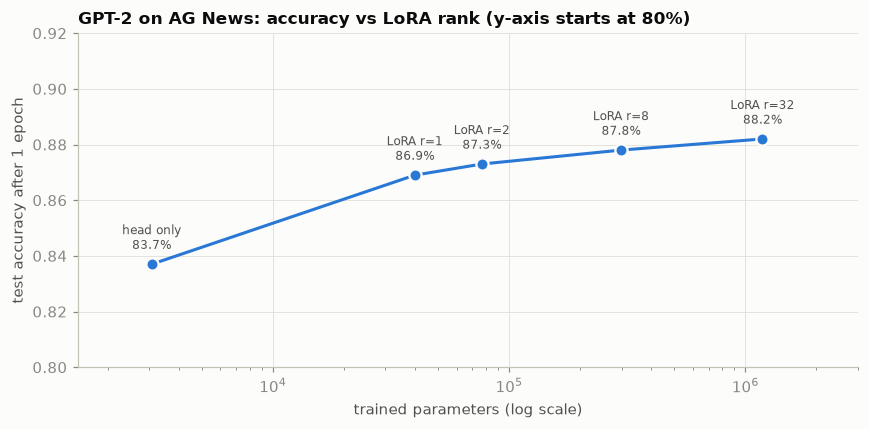

,configuration,trained parameters,share of model,accuracy,F1,train seconds
0,head only,"3,072",0.002%,0.837,0.835,16.842
1,LoRA r=1,"39,936",0.032%,0.869,0.869,36.375
2,LoRA r=2,"76,800",0.062%,0.873,0.873,37.131
3,LoRA r=8,"297,984",0.239%,0.878,0.878,38.643
4,LoRA r=32,"1,182,720",0.950%,0.882,0.882,38.438


In [20]:
# Figure 4: accuracy against the number of trained parameters
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep["trained parameters"], sweep["accuracy"], color=BLUE, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
for _, row in sweep.iterrows():
    ax.annotate(f"{row['configuration']}\n{row['accuracy']:.1%}", xy=(row["trained parameters"], row["accuracy"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8, color=SECONDARY)
ax.set_xscale("log")
ax.set(xlabel="trained parameters (log scale)", ylabel="test accuracy after 1 epoch",
       title="GPT-2 on AG News: accuracy vs LoRA rank (y-axis starts at 80%)", ylim=(0.80, 0.92), xlim=(1.5e3, 3e6))
fig.tight_layout()
fig.savefig("assets/rank-sweep.png")
plt.show()

table = sweep.drop(columns="rank").copy()
table["trained parameters"] = table["trained parameters"].map("{:,}".format)
table["share of model"] = table["share of model"].map("{:.3%}".format)
table.round(3)

**What the sweep shows.**

- **The frozen model is already a good feature extractor.** Training nothing but the 3,072-parameter head gives 83.7%. Most of the jump from 27% is the head learning to read features that were already there.
- **The first rank is worth more than the next thirty-one.** A rank-1 adapter lifts accuracy by 3.2 points over head-only, to 86.9%. Going from rank 1 to rank 32, with 32 times as many adapter parameters, adds 1.3 points more. The curve rises with rank but is nearly flat, which is what the low-intrinsic-dimension argument for LoRA predicts (Aghajanyan et al., 2020): the update this task needs fits in very few directions.
- **Neighbouring ranks cannot be told apart.** With 1,000 test items the sampling error on each accuracy is about ±2 points, larger than the gap between adjacent LoRA settings, and this is one seed.
- **Rank does not change the training cost.** Every LoRA configuration took 36 to 39 seconds, from rank 1 to rank 32, against about 17 seconds for head-only. The cost is the backward pass through the network, which is needed as soon as any adapter exists and does not depend on its size.
- **None of these one-epoch runs beats the submitted model** (89.4% after two epochs in Section 8).

## B. QLoRA: can the frozen model be stored in 4 bits?

Most of the memory in LoRA fine-tuning goes to the frozen model, which is never updated. QLoRA (Dettmers et al., 2023) stores the frozen base model in **4 bits per weight** instead of 32, and trains ordinary LoRA adapters on top of it. The adapters and the head stay in full precision; only the frozen weights are compressed. During each forward pass a 4-bit block is temporarily expanded back to 16-bit to do the multiplication, then discarded.

Three settings in `BitsAndBytesConfig` come from the QLoRA paper:

| Setting | Value | Meaning |
|---|---|---|
| `bnb_4bit_quant_type` | `"nf4"` | *NormalFloat-4*: the 16 representable values are placed at the quantiles of a normal distribution, which matches how trained weights are distributed |
| `bnb_4bit_use_double_quant` | `True` | The per-block scaling constants are themselves quantized, saving a little more memory |
| `bnb_4bit_compute_dtype` | `float16` | The precision the 4-bit weights are expanded to for each multiplication |

`bitsandbytes` historically required an NVIDIA GPU. Recent versions also support Apple Silicon, so this runs on the laptop's GPU as well as in a CUDA workspace. The cell checks for a supported device first and skips cleanly if there is none.

One detail changes from the LoRA config above: quantization replaces GPT-2's transposed `Conv1D` layers with standard `Linear4bit` layers, so `fan_in_fan_out` must now be `False`.

In [21]:
import importlib.util

qlora_available = importlib.util.find_spec("bitsandbytes") is not None and DEVICE in ("cuda", "mps")

if not qlora_available:
    print("Skipping QLoRA: it needs the bitsandbytes package and a CUDA or Apple Silicon GPU.")
else:
    import bitsandbytes
    from peft import prepare_model_for_kbit_training
    from transformers import BitsAndBytesConfig

    logging.getLogger("torch._dynamo").setLevel(logging.ERROR)   # silence compiler notices from the 4-bit kernels

    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )

    transformers.set_seed(42)
    qlora_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id,
        quantization_config=quant_config, device_map={"": DEVICE}, **MODEL_KWARGS,
    )
    qlora_model.config.pad_token_id = qlora_model.config.eos_token_id
    footprint_4bit = qlora_model.get_memory_footprint()

    qlora_model = prepare_model_for_kbit_training(qlora_model, use_gradient_checkpointing=False)
    qlora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
        target_modules=["c_attn"], fan_in_fan_out=False,   # Linear4bit is not transposed
    )
    qlora_model = get_peft_model(qlora_model, qlora_config)
    print(f"bitsandbytes {bitsandbytes.__version__} on {DEVICE} | c_attn is now {type(qlora_model.base_model.model.transformer.h[0].attn.c_attn.base_layer).__name__}")
    qlora_model.print_trainable_parameters()

    qlora_seconds = train_one_epoch(qlora_model)
    qlora_results, _ = evaluate_model(qlora_model)

    footprint_32bit = load_base_model().get_memory_footprint()
    lora_row = sweep[sweep["rank"] == 8].iloc[0]

    qlora_table = pd.DataFrame(
        {
            "base model weights": ["32-bit", "4-bit (NF4)"],
            "model in memory (MB)": [footprint_32bit / 1024**2, footprint_4bit / 1024**2],
            "trained parameters": [f"{int(lora_row['trained parameters']):,}"] * 2,
            "accuracy after 1 epoch": [lora_row["accuracy"], qlora_results["eval_accuracy"]],
            "F1": [lora_row["F1"], qlora_results["eval_f1"]],
            "train seconds": [lora_row["train seconds"], qlora_seconds],
        },
        index=["LoRA r=8", "QLoRA r=8"],
    )
    del qlora_model

qlora_table.round(3) if qlora_available else None

bitsandbytes 0.50.2 on mps | c_attn is now Linear4bit
trainable params: 297,984 || all params: 124,740,864 || trainable%: 0.2389


,base model weights,model in memory (MB),trained parameters,accuracy after 1 epoch,F1,train seconds
LoRA r=8,32-bit,474.712,"297,984",0.878,0.878,38.643
QLoRA r=8,4-bit (NF4),191.212,"297,984",0.889,0.889,29.371


In [22]:
# Where the memory goes: count the 4-bit and full-precision parameters of the quantized model
if qlora_available:
    probe = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), quantization_config=quant_config, device_map={"": DEVICE}, **MODEL_KWARGS
    )
    quantized = sum(m.weight.numel() * 2 for m in probe.modules() if isinstance(m, bitsandbytes.nn.Linear4bit))  # 2 weights per stored byte
    full_precision = sum(p.numel() for name, p in probe.named_parameters() if p.dtype != torch.uint8)
    embeddings = probe.transformer.wte.weight.numel() + probe.transformer.wpe.weight.numel()
    del probe

    print(f"weights stored in 4 bits      : {quantized:>11,}  x 0.5 bytes = {quantized * 0.5 / 1024**2:6.1f} MB")
    print(f"weights kept in full precision: {full_precision:>11,}  x 4 bytes   = {full_precision * 4 / 1024**2:6.1f} MB")
    print(f"  of which token + position embeddings: {embeddings:,} ({embeddings / total_params:.0%} of GPT-2)")
    print(f"sum (before small quantization constants): {(quantized * 0.5 + full_precision * 4) / 1024**2:.1f} MB "
          f"| measured: {footprint_4bit / 1024**2:.1f} MB")

weights stored in 4 bits      :  84,934,656  x 0.5 bytes =   40.5 MB
weights kept in full precision:  39,508,224  x 4 bytes   =  150.7 MB
  of which token + position embeddings: 39,383,808 (32% of GPT-2)
sum (before small quantization constants): 191.2 MB | measured: 191.2 MB


**What QLoRA changed.**

| | LoRA r=8 | QLoRA r=8 |
|---|---:|---:|
| Frozen base weights stored as | 32-bit | 4-bit NF4 |
| Model in memory | 474.7 MB | **191.2 MB** |
| Trained parameters | 297,984 | 297,984 |
| Accuracy after 1 epoch | 87.8% | 88.9% |
| Training time on this Mac | about 39 s | about 29 s |

**Memory, step by step.** The quantized model's 191.2 MB is fully accounted for:

1. The linear layers (attention and feed-forward in all 12 blocks) hold 84,934,656 weights. At 4 bits, two weights fit in one byte: $84{,}934{,}656 \times 0.5 = 42{,}467{,}328$ bytes $= 40.5$ MB.
2. Everything else stays in full precision: 39,508,224 parameters $\times\, 4$ bytes $= 158{,}032{,}896$ bytes $= 150.7$ MB.
3. Total: $40.5 + 150.7 = 191.2$ MB, exactly what was measured.

The saving is 2.5x, not the 8x that "32 bits down to 4" suggests, and step 2 shows why. QLoRA only quantizes linear layers, and in GPT-2 the token and position embeddings are 39.4M parameters, **32% of the model**, which stay in 32-bit. In a multi-billion-parameter model the embedding table is a far smaller share, so the saving gets much closer to the full factor. That is the setting QLoRA was designed for.

**Accuracy did not suffer.** 88.9% against 87.8% for the same adapter on the full-precision model is within the ±2-point sampling error of a 1,000-item test set: no measurable loss from quantization. It is also below the submitted two-epoch model's 89.4%.

**Speed.** QLoRA trained faster here, probably because its computations run in 16-bit instead of 32-bit. I would not generalize that: on many GPUs QLoRA is *slower* than LoRA, because every forward pass has to expand the 4-bit weights first. Its purpose is memory, not speed.

# Summary

| Project requirement | Section | Result |
|---|---|---|
| Load a pretrained Hugging Face model | 1 | `gpt2` with `AutoModelForSequenceClassification`, 4 labels |
| Load and preprocess a dataset | 2 | AG News, 4,000 train / 1,000 test, GPT-2 `AutoTokenizer` |
| Evaluate the pretrained model | 3 | As-is: accuracy 27.0%, precision 0.245, recall 0.254, F1 0.115. Zero-shot: accuracy 62.5% |
| Create a PEFT model | 4 | `LoraConfig` (r = 8) + `get_peft_model`, 297,984 trainable parameters |
| Train the PEFT model | 5 | 2 epochs with `Trainer` |
| Save the PEFT model | 6 | `gpt2-lora-ag-news/` next to this notebook, 1.14 MB of adapter weights |
| Load the saved PEFT model | 7 | `AutoPeftModelForSequenceClassification.from_pretrained` |
| Evaluate the fine-tuned model | 8 | Same evaluation: **accuracy 89.4%**, precision 0.895, recall 0.894, F1 0.894, the best of all models |
| Experiment: LoRA rank | Further experiments, A | Head-only and LoRA ranks 1, 2, 8, 32 |
| Experiment: QLoRA | Further experiments, B | GPT-2 held in 4 bits: 191 MB instead of 475 MB in memory, 88.9% after one epoch |

**Limitations.**

- **The untrained-head baseline is a floor.** A randomly initialized head makes the original model look worse than its features are. The zero-shot baseline and the head-only run in experiment A are fairer reference points, and the fine-tuned model beats both.
- **A 4,000-item subset and one seed.** More training data would raise every number, and the differences inside the rank sweep are within noise.
- **The test set is also used to report per-epoch metrics during training.** No model selection is done on it (the final epoch is always used), but a separate validation split would be the cleaner protocol.

**Files submitted:** this notebook and the `gpt2-lora-ag-news/` directory (`adapter_config.json`, `adapter_model.safetensors` and the tokenizer files).

## References

- Hu et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Dettmers, Pagnoni, Holtzman & Zettlemoyer (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)
- Radford et al. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2).
- Aghajanyan, Zettlemoyer & Gupta (2020). *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning.* [arXiv:2012.13255](https://arxiv.org/abs/2012.13255)
- Hugging Face PEFT documentation: [LoRA](https://huggingface.co/docs/peft/package_reference/lora), [AutoPeftModel](https://huggingface.co/docs/peft/package_reference/auto_class) and [configuration](https://huggingface.co/docs/peft/package_reference/config)
- AG News dataset: [fancyzhx/ag_news](https://huggingface.co/datasets/fancyzhx/ag_news) on the Hugging Face Hub